# MU copy: $\lambda=0.1$, $T=3.6$, five thimbles

Copy of `Complex_Time_QHO_Anharmonic_MU.ipynb`. The original is not modified.
Same rank-16 saddle flow. Extra change: search the second bounce family and, when it is distinct, train it and add $2K_{b_2}$.

Physical cycle aimed for:
$$K = K_0 + 2K_{b_1} + 2K_{b_2}.$$

Target is the same-$N$ lattice FFT at $\lambda=0.1$, $T=3.6$ (the point that was ~32% off with the trivial thimble).


In [1]:
from __future__ import annotations

import csv
import json
import math
import os
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg
import torch
import torch.nn as nn
from scipy.optimize import root

%matplotlib inline

torch.set_default_dtype(torch.float64)

# Physics: only the requested lambda=0.7 run.
N = 16
D = N - 1
DT = 0.2
T_LIST = [round(2.0 + i * DT, 2) for i in range(int(round((4.0 - 2.0) / DT)) + 1)]
T = float(T_LIST[0])
ETA = 0.05
MASS = 1.0
OMEGA = 1.0
# Override from a terminal/runner with MU_LAMBDA=2.4 or MU_LAMBDA=3.0.
LAMBDA = 0.1
A_C = (T - 1j * ETA) / N
X_I = X_F = 0.0 

# Fastest configuration tested to remain statistically meaningful.
RANK = 16
EPOCHS = 1_000
BATCH = 512
LEARNING_RATE = 1.0e-3
N_MC = 80_000
MC_CHUNK = 5_000
SEED = 52
LOG_EVERY = 250

# Set True only for a syntax check; its numbers are not physics results.
QUICK_TEST = False
if QUICK_TEST:
    EPOCHS, BATCH, N_MC, MC_CHUNK, LOG_EVERY = 5, 32, 1_000, 500, 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
run_dir = Path("runs") / f"{stamp}_MU_multithimble_lambda{LAMBDA:g}_N{N}"
run_dir.mkdir(parents=True, exist_ok=True)

print(f"device={DEVICE}; dtype=float64/complex128")
print(f"N={N}, D={D}, T_c={T}-{ETA}i, lambda={LAMBDA}")
print(f"rank={RANK}, epochs={EPOCHS} per saddle, batch={BATCH}, N_mc={N_MC}")
print(f"run directory: {run_dir.resolve()}")

device=cpu; dtype=float64/complex128
N=16, D=15, T_c=2.0-0.05i, lambda=0.1
rank=16, epochs=1000 per saddle, batch=512, N_mc=80000
run directory: C:\xampp1\Quantum\runs\20261001_143307_MU_multithimble_lambda0.1_N16


## 1. Lattice action and stationary points

For zero endpoints, the $D=N-1$ complex interior coordinates have action

$$S[x]=\frac{m}{2a_c}\sum_{k=0}^{N-1}(x_{k+1}-x_k)^2
-\frac{a_cm\omega^2}{2}\sum_{k=1}^{N-1}x_k^2
-\frac{a_c\lambda}{4}\sum_{k=1}^{N-1}x_k^4,$$

with $a_c=(T-i\eta)/N$ and weight $e^{iS}$.  Unlike the harmonic oscillator, the hard
quartic oscillator has nonzero zero-to-zero solutions even when $T<\pi/\omega$: increasing
amplitude raises its frequency.  The previous notebook incorrectly retained only $x=0$.

In [2]:
def action_np(x: np.ndarray) -> complex:
    """Discretised complex-time action for one path."""
    padded = np.r_[0.0 + 0.0j, x, 0.0 + 0.0j]
    dx = np.diff(padded)
    return (
        MASS / (2.0 * A_C) * np.sum(dx**2)
        - A_C * MASS * OMEGA**2 / 2.0 * np.sum(x**2)
        - A_C * LAMBDA / 4.0 * np.sum(x**4)
    )


def gradient_np(x: np.ndarray) -> np.ndarray:
    """Holomorphic gradient dS/dx at the interior lattice sites."""
    padded = np.r_[0.0 + 0.0j, x, 0.0 + 0.0j]
    return (
        (MASS / A_C) * (2.0 * x - padded[:-2] - padded[2:])
        - A_C * MASS * OMEGA**2 * x
        - A_C * LAMBDA * x**3
    )


def hessian_np(x: np.ndarray) -> np.ndarray:
    """Complex-symmetric Hessian d^2S/dx_j dx_k at a saddle."""
    hessian = np.zeros((D, D), dtype=np.complex128)
    np.fill_diagonal(
        hessian,
        2.0 * MASS / A_C
        - A_C * MASS * OMEGA**2
        - 3.0 * A_C * LAMBDA * x**2,
    )
    np.fill_diagonal(hessian[1:], -MASS / A_C)
    np.fill_diagonal(hessian[:, 1:], -MASS / A_C)
    return hessian


def packed_gradient(y: np.ndarray) -> np.ndarray:
    x = y[:D] + 1j * y[D:]
    grad = gradient_np(x)
    return np.r_[grad.real, grad.imag]


def action_torch(x: torch.Tensor) -> torch.Tensor:
    """Batch action accumulated entirely in complex128."""
    x = x.to(torch.complex128)
    zero = torch.zeros((x.shape[0], 1), dtype=torch.complex128, device=x.device)
    padded = torch.cat((zero, x, zero), dim=1)
    dx = padded[:, 1:] - padded[:, :-1]
    a = torch.as_tensor(A_C, dtype=torch.complex128, device=x.device)
    return (
        MASS / (2.0 * a) * torch.sum(dx**2, dim=1)
        - a * MASS * OMEGA**2 / 2.0 * torch.sum(x**2, dim=1)
        - a * LAMBDA / 4.0 * torch.sum(x**4, dim=1)
    )

## 2. Locate the missing bounce and construct local thimble tangents

The first nonzero saddle is found from sine-wave initial guesses and refined against the
full complex lattice equations.  Its parity partner $-x_{\rm b}$ has exactly the same action
and Hessian because the potential is even.

At each saddle, a complex-orthogonal eigendecomposition builds $A_\sigma$ satisfying

$$A_\sigma^T H_\sigma A_\sigma=iI,$$

so $x=x_\sigma+A_\sigma z$ starts on the exact local steepest-descent tangent.  The saddle and
this linear map remain fixed during training, preventing either network from drifting into
the zero saddle or flipping orientation.

In [3]:
def find_bounce_harmonic(harmonic: int) -> list:
    """Nonzero zero-endpoint saddles from a sine guess of the given harmonic."""
    sites = np.arange(1, N)
    shape = np.sin(harmonic * np.pi * sites / N)
    candidates = []
    for amplitude in np.linspace(0.4, 12.0, 30):
        guess = np.r_[amplitude * shape, np.zeros(D)]
        solved = root(packed_gradient, guess, method="lm", options={"maxiter": 5_000})
        x = solved.x[:D] + 1j * solved.x[D:]
        residual = np.max(np.abs(gradient_np(x)))
        if residual < 1e-8 and np.max(np.abs(x)) > 1e-3:
            if not any(np.max(np.abs(x - old)) < 1e-6 for old in candidates):
                if not any(np.max(np.abs(x + old)) < 1e-6 for old in candidates):
                    candidates.append(x)
    return candidates


def first_bounce() -> np.ndarray:
    """Lowest-|S| one-hump bounce. Same idea as the original scan, wider amplitudes."""
    candidates = find_bounce_harmonic(1)
    if not candidates:
        raise RuntimeError("Could not find the first nonzero saddle")
    return min(candidates, key=lambda x: abs(action_np(x)))


def second_bounce(first: np.ndarray):
    """Next distinct bounce family (two-hump / three-hump guesses). Counted twice by parity."""
    pool = find_bounce_harmonic(2) + find_bounce_harmonic(3)
    distinct = []
    for x in pool:
        if np.max(np.abs(x - first)) < 1e-3 or np.max(np.abs(x + first)) < 1e-3:
            continue
        if np.max(np.abs(x)) < 1e-3:
            continue
        if any(np.max(np.abs(x - old)) < 1e-5 or np.max(np.abs(x + old)) < 1e-5 for old in distinct):
            continue
        distinct.append(x)
    if not distinct:
        return None
    return min(distinct, key=lambda x: action_np(x).imag)


def tangent_map(hessian: np.ndarray) -> np.ndarray:
    """Return canonically oriented A with A.T @ H @ A = iI."""
    values, vectors = np.linalg.eig(hessian)
    for k in range(D):
        vectors[:, k] /= np.sqrt(vectors[:, k].T @ vectors[:, k])

    # Complex orthogonality implies det(V)=+/-1.  Fix +1 so every saddle uses
    # the same orientation inherited from the real coordinate basis; otherwise
    # a LAPACK eigenvector sign arbitrarily changes K_sigma -> -K_sigma.
    if np.linalg.det(vectors).real < 0.0:
        vectors[:, 0] *= -1.0

    orthogonal_error = np.max(np.abs(vectors.T @ vectors - np.eye(D)))
    orientation_error = abs(np.linalg.det(vectors) - 1.0)
    tangent = vectors @ np.diag(np.sqrt(1j / values))
    residual = np.max(np.abs(tangent.T @ hessian @ tangent - 1j * np.eye(D)))
    if orthogonal_error > 1e-8 or orientation_error > 1e-8 or residual > 1e-8:
        raise RuntimeError(
            "Bad saddle tangent: "
            f"orthogonal={orthogonal_error}, orientation={orientation_error}, "
            f"congruence={residual}"
        )
    return tangent


def fixed_n_reference(basis_size: int = 300) -> complex:
    """Independent deterministic evaluation of this exact N-slice path integral."""
    nb = int(basis_size)
    lowering = np.zeros((nb, nb), dtype=np.float64)
    idx = np.arange(1, nb)
    lowering[idx - 1, idx] = np.sqrt(idx)
    x_op = (lowering + lowering.T) / np.sqrt(2.0)
    p_op = (lowering - lowering.T) / (1j * np.sqrt(2.0))
    x2 = x_op @ x_op

    kinetic = p_op @ p_op / (2.0 * MASS)
    ep, up = scipy.linalg.eigh(kinetic)
    free_step = (up * np.exp(-1j * A_C * ep)) @ up.conj().T

    potential = MASS * OMEGA**2 * x2 / 2.0 + LAMBDA * (x2 @ x2) / 4.0
    ev, uv = scipy.linalg.eigh(potential)
    potential_step = (uv * np.exp(-1j * A_C * ev)) @ uv.conj().T

    position_zero = np.zeros(nb, dtype=np.float64)
    for n in range(0, nb, 2):
        q = n // 2
        position_zero[n] = (-1.0)**q * math.exp(
            0.5 * math.lgamma(2 * q + 1) - q * math.log(2.0)
            - math.lgamma(q + 1) - 0.25 * math.log(np.pi)
        )

    evolution = free_step.copy()
    for _ in range(N - 1):
        evolution = evolution @ potential_step @ free_step
    return complex(position_zero @ evolution @ position_zero)


def gaussian_saddle_estimate(saddle: np.ndarray) -> complex:
    """Quadratic saddle estimate; used only as a decomposition diagnostic."""
    hessian = hessian_np(saddle)
    norm = (MASS / (2.0 * np.pi * 1j * A_C)) ** (N / 2)
    return complex(
        norm * np.exp(1j * action_np(saddle))
        * (2.0 * np.pi * 1j) ** (D / 2) / np.sqrt(np.linalg.det(hessian))
    )

## 3. Saddle-anchored neural contour

For each saddle $x_\sigma$ the learned map is

$$x(z)=x_\sigma+A_\sigma z+C\tanh\!\left(W_2\tanh(W_1z)\right).$$

There are no neural biases, so $g(0)=0$ and the contour always passes through its assigned
saddle.  $A_\sigma$ and $x_\sigma$ are buffers rather than trainable parameters.  Only the
rank-16 nonlinear correction learns.

The full Jacobian is

$$J=A_\sigma+C D_2W_2D_1W_1.$$

For `x = z @ A.T`, Sylvester's identity requires **`solve(A, C)`**.  The old notebook used
`solve(A.T, C)`, i.e. $A^{-T}C$, which is the transpose bug identified in
`Re__Complex_Time_Code_/note_for_tom.pdf`.

In [4]:
class SaddleFlow(nn.Module):
    """Fixed saddle/tangent plus a saddle-anchored low-rank correction."""

    def __init__(self, saddle: np.ndarray, tangent: np.ndarray, seed: int):
        super().__init__()
        torch.manual_seed(seed)
        self.register_buffer(
            "saddle", torch.tensor(saddle, dtype=torch.complex128, device=DEVICE)
        )
        self.register_buffer(
            "A", torch.tensor(tangent, dtype=torch.complex128, device=DEVICE)
        )
        self.W1 = nn.Parameter(torch.randn(RANK, D, device=DEVICE) / math.sqrt(D))
        qmat, _ = torch.linalg.qr(torch.randn(RANK, RANK, device=DEVICE))
        self.W2 = nn.Parameter(qmat)
        # Tiny rather than exactly zero so every layer receives a gradient on step one.
        self.C_real = nn.Parameter(1e-5 * torch.randn(D, RANK, device=DEVICE))
        self.C_imag = nn.Parameter(1e-5 * torch.randn(D, RANK, device=DEVICE))

    def C(self) -> torch.Tensor:
        return self.C_real.to(torch.complex128) + 1j * self.C_imag.to(torch.complex128)

    def forward(self, z: torch.Tensor, return_cache: bool = False):
        z = z.to(dtype=torch.float64, device=DEVICE)
        a1 = torch.tanh(z @ self.W1.T)
        a2 = torch.tanh(a1 @ self.W2.T)
        x = (
            z.to(torch.complex128) @ self.A.T
            + self.saddle
            + a2.to(torch.complex128) @ self.C().T
        )
        return (x, (a1, a2)) if return_cache else x

    def full_jacobian(self, a1: torch.Tensor, a2: torch.Tensor) -> torch.Tensor:
        """Exact batch Jacobian A + C D2 W2 D1 W1, including all cross terms."""
        d1 = 1.0 - a1**2
        d2 = 1.0 - a2**2
        h1 = d1.unsqueeze(-1) * self.W1.unsqueeze(0)
        h2 = torch.matmul(self.W2.unsqueeze(0), h1)
        dh_dz = d2.unsqueeze(-1) * h2
        correction = torch.matmul(self.C().unsqueeze(0), dh_dz.to(torch.complex128))
        return self.A.unsqueeze(0) + correction

    def determinant_parts(self, a1: torch.Tensor, a2: torch.Tensor):
        """Return log|det J| and det(J)/|det(J)| via the corrected low-rank formula."""
        sign_a, logabs_a = torch.linalg.slogdet(self.A)
        # Correct for forward x = z @ A.T.  This is A^{-1}C, not A^{-T}C.
        k_mat = self.W1.to(torch.complex128) @ torch.linalg.solve(self.A, self.C())
        d1 = (1.0 - a1**2).to(torch.complex128)
        d2 = (1.0 - a2**2).to(torch.complex128)
        m1 = d1.unsqueeze(-1) * k_mat.unsqueeze(0)
        m2 = torch.matmul(self.W2.to(torch.complex128).unsqueeze(0), m1)
        correction = (
            torch.eye(RANK, dtype=torch.complex128, device=DEVICE).unsqueeze(0)
            + d2.unsqueeze(-1) * m2
        )
        sign_c, logabs_c = torch.linalg.slogdet(correction)
        return logabs_a + logabs_c, sign_a * sign_c

## 4. Preflight checks

Before training, the notebook verifies:

1. the bounce residual $\|\partial S/\partial x\|_\infty$;
2. parity: $S[x_b]=S[-x_b]$ and $H[x_b]=H[-x_b]$;
3. $A_\sigma^T H_\sigma A_\sigma=iI$;
4. the analytic full Jacobian against central finite differences;
5. the corrected low-rank determinant against `det(full_jacobian)`.

The quadratic saddle estimates provide an independent scale check.  Already at Gaussian
order, subtracting the bounce pair shifts the zero-saddle answer in precisely the direction
required by the deterministic reference.

In [5]:
def validate_saddles_and_jacobian(trivial: np.ndarray, bounce: np.ndarray) -> None:
    residual = np.max(np.abs(gradient_np(bounce)))
    parity_action = abs(action_np(bounce) - action_np(-bounce))
    parity_hessian = np.max(np.abs(hessian_np(bounce) - hessian_np(-bounce)))
    if residual > 1e-8 or parity_action > 1e-10 or parity_hessian > 1e-10:
        raise RuntimeError("Saddle or parity preflight failed")

    tangent = tangent_map(hessian_np(bounce))
    model = SaddleFlow(bounce, tangent, SEED + 999)
    # Make the nonlinear correction large enough that the check tests it, not only A.
    with torch.no_grad():
        model.C_real.normal_(std=0.03)
        model.C_imag.normal_(std=0.03)

    z = torch.randn(3, D, dtype=torch.float64, device=DEVICE)
    x, (a1, a2) = model(z, return_cache=True)
    jacobian = model.full_jacobian(a1, a2)
    eps = 1e-6
    jacobian_fd = torch.empty_like(jacobian)
    with torch.no_grad():
        for k in range(D):
            dz = torch.zeros_like(z)
            dz[:, k] = eps
            jacobian_fd[:, :, k] = (model(z + dz) - model(z - dz)) / (2.0 * eps)
    fd_error = float(torch.max(torch.abs(jacobian - jacobian_fd)).cpu())

    logabs, sign = model.determinant_parts(a1, a2)
    det_low_rank = torch.exp(logabs) * sign
    det_full = torch.linalg.det(jacobian)
    determinant_error = float(torch.max(torch.abs(det_low_rank - det_full)).cpu())
    determinant_relative = determinant_error / max(
        float(torch.max(torch.abs(det_full)).cpu()), 1e-300
    )

    print(f"bounce residual              : {residual:.3e}")
    print(f"parity action/Hessian errors : {parity_action:.3e}, {parity_hessian:.3e}")
    print(f"full Jacobian FD error       : {fd_error:.3e}")
    print(f"low-rank determinant rel err : {determinant_relative:.3e}")
    if fd_error > 3e-7 or determinant_relative > 3e-8:
        raise RuntimeError("Corrected Jacobian preflight failed")
    print("All saddle and Jacobian preflight checks PASSED")

## 5. Branch-safe training and complex importance weights

For standard-normal $z$, write the weight without taking a complex logarithm:

$$\log|W|=-\operatorname{Im}S+\log|\det J|-\log P(z),\qquad
u_W=e^{i\operatorname{Re}S}\frac{\det J}{|\det J|}.$$

The objective is

$$\operatorname{Var}[\log|W|]+1-|\langle\nu_W\rangle|^2.$$

The second term is circular phase variance; unlike `Var(Im(log W))`, it has no artificial
branch cut at $\pm\pi$.  Estimation retains the required
$W=e^{iS}\det J/P$ and the original complex-time normalization.  Five independent MC
blocks expose sampling instability.

In [6]:
LOG_2PI = math.log(2.0 * math.pi)


def weight_parts(model: SaddleFlow, z: torch.Tensor):
    """Branch-safe representation of exp(iS) det(J) / P(z)."""
    x, (a1, a2) = model(z, return_cache=True)
    action = action_torch(x)
    logabs_j, sign_j = model.determinant_parts(a1, a2)
    log_p = -0.5 * torch.sum(z**2, dim=1) - 0.5 * D * LOG_2PI
    logabs_w = -action.imag + logabs_j - log_p
    phase_w = torch.exp(1j * action.real) * sign_j
    return logabs_w, phase_w


def train_thimble(label: str, saddle: np.ndarray, seed: int):
    tangent = tangent_map(hessian_np(saddle))
    model = SaddleFlow(saddle, tangent, seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS, eta_min=LEARNING_RATE * 0.05
    )
    history = {"total": [], "logmag": [], "phase": []}
    started = time.time()

    for epoch in range(EPOCHS):
        optimizer.zero_grad(set_to_none=True)
        z = torch.randn(BATCH, D, dtype=torch.float64, device=DEVICE)
        logabs_w, phase_w = weight_parts(model, z)
        logmag_variance = torch.var(logabs_w, unbiased=False)
        circular_phase = 1.0 - torch.abs(torch.mean(phase_w))**2
        loss = logmag_variance + circular_phase
        if not torch.isfinite(loss):
            raise FloatingPointError(f"{label}: nonfinite loss at epoch {epoch + 1}")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        scheduler.step()

        history["total"].append(float(loss.detach().cpu()))
        history["logmag"].append(float(logmag_variance.detach().cpu()))
        history["phase"].append(float(circular_phase.detach().cpu()))
        if epoch == 0 or (epoch + 1) % LOG_EVERY == 0 or epoch + 1 == EPOCHS:
            print(
                f"{label:8s} epoch {epoch+1:4d}/{EPOCHS}: "
                f"loss={history['total'][-1]:.3e}, "
                f"logmag={history['logmag'][-1]:.3e}, "
                f"phase={history['phase'][-1]:.3e}, "
                f"elapsed={time.time()-started:.0f}s",
                flush=True,
            )
    return model, history, time.time() - started


def estimate_thimble(model: SaddleFlow, seed: int):
    """Chunked complex128 MC estimate with five independent stability blocks."""
    torch.manual_seed(seed + 100_000)
    logs, phases = [], []
    remaining = N_MC
    model.eval()
    while remaining:
        count = min(MC_CHUNK, remaining)
        z = torch.randn(count, D, dtype=torch.float64, device=DEVICE)
        with torch.no_grad():
            logabs, phase = weight_parts(model, z)
        logs.append(logabs.cpu())
        phases.append(phase.cpu())
        remaining -= count

    logabs = torch.cat(logs)
    phase = torch.cat(phases)
    shift = torch.max(logabs)
    shifted = torch.exp(logabs - shift) * phase
    norm = (MASS / (2.0 * np.pi * 1j * A_C)) ** (N / 2)
    scale = norm * math.exp(float(shift))
    estimate = complex(scale * torch.mean(shifted).numpy())

    centered = shifted - torch.mean(shifted)
    stderr = abs(scale) * math.sqrt(float(torch.mean(torch.abs(centered)**2)) / N_MC)
    ess = float(
        torch.abs(torch.mean(shifted))**2 / torch.mean(torch.abs(shifted)**2)
    )
    blocks = [
        complex(scale * torch.mean(block).numpy())
        for block in torch.tensor_split(shifted, 5)
    ]
    block_scatter = float(np.std(np.asarray(blocks, dtype=np.complex128)))
    return estimate, stderr, ess, block_scatter, blocks

## 6. Find and validate the two required saddle sectors

The deterministic basis calculation evaluates the identical $N=16$ Trotterized path
integral and supplies the acceptance target.  It is independent of the ML contour and MC
estimator.

For the discovered saddle, this cell also prints its action and the quadratic estimates.
The higher-action bounce families are exponentially suppressed for the selected couplings;
the first parity pair is the missing contribution visible at the precision requested here.
The canonical tangent orientation makes each real-cycle intersection coefficient `+1`; the
sign of each saddle contribution is then carried by its Jacobian.

In [7]:
print('Single-T cell skipped. The T=2..4 loop is the last cell.')


Single-T cell skipped. The T=2..4 loop is the last cell.


## 7. Train the zero and bounce thimbles, then combine them

Only two networks are trained for the selected value of $\lambda$:

- `trivial`: the thimble through $x=0$, coefficient $+1$;
- `bounce`: the thimble through the first positive bounce.  Parity gives an equal negative
  bounce saddle.  Both lie on the real stationary cycle and have intersection coefficient
  $+1$, hence total coefficient $+2$ in the canonical tangent orientation.

The old notebook reported `K_trivial` as if it were the full answer.  This cell reports both
that baseline and the physical-cycle sum.

In [8]:
print('Single-T cell skipped. The T=2..4 loop is the last cell.')


Single-T cell skipped. The T=2..4 loop is the last cell.


## 8. Save checkpoints, CSV, JSON, report, and loss curves

All numerical values are written immediately into the timestamped run directory.  The CSV
contains both individual thimble contributions and the corrected physical sum, making it
impossible to confuse the old zero-saddle result with the propagator.

In [9]:
print('Single-T cell skipped. The T=2..4 loop is the last cell.')


Single-T cell skipped. The T=2..4 loop is the last cell.


## 9. Visual comparison and acceptance check

The complex-plane plot shows exactly what changed: the zero-saddle answer stays near the old
nearly harmonic value, while subtracting the nonzero parity pair moves it onto the
same-$N$ anharmonic reference.  A run is accepted only when the corrected complex relative
error is below 5%, both individual ESS values are finite, and MC block scatter is controlled.

In [10]:
print('Single-T cell skipped. The T=2..4 loop is the last cell.')


Single-T cell skipped. The T=2..4 loop is the last cell.


## 10. Time scan $T=2\to 4$, $\Delta T=0.2$, $\lambda=0.1$

Same five-thimble sum $K_0+2K_{b_1}+2K_{b_2}$ at each time. A missing family is left out. Compared to the same-$N$ lattice FFT.


LAMBDA=0.1  T_LIST=[2.0, 2.2, 2.4, 2.6, 2.8, 3.0, 3.2, 3.4, 3.6, 3.8, 4.0]



####################################################################################


T = 2.0   lambda = 0.1


####################################################################################


bounce1=True  bounce2=True


...

bounce2  epoch 1000/1000: loss=8.167e-02, logmag=4.141e-02, phase=4.026e-02, elapsed=50s


K_bounce2=-0.1183865715-0.0099207314j  ESS/N=0.864152  50s


K_ML=-0.5222188921-0.3488841897j
K_lattice=-0.5216485740-0.3491529993j
error=0.100%  PASS


Wrote 11 rows to runs\20261001_143307_MU_multithimble_lambda0.1_N16\MU_lambda0p1_T2to4_dt0.2_5thimble_vs_lattice.csv



     T                        K_ML                   K_lattice      err%     b1     b2    status
------------------------------------------------------------------------------------------------
  2.00  +0.248758-0.612109j  +0.248842-0.611896j    0.035%   True   True      PASS
  2.20  +0.398646+0.189752j  +0.397506+0.189026j    0.307%   True   True      PASS
  2.40  +0.926094-0.583493j  +0.928836-0.580316j    0.383%   True   True      PASS
  2.60  +0.397489-1.050880j  +0.409422-1.059506j    1.296%   True   True      PASS
  2.80  +3.143007+2.528856j  -0.039702-0.983907j  481.378%   True   True      FAIL
  3.00  -47146451432904876032.000000-10630514204565690368.000000j  -0.226099-0.782216j  5935626696120812437504.000%   True   True      FAIL
  3.20  -0.271392-0.637203j  -0.278002-0.636902j    0.952%  False   True      PASS
  3.40  -0.350591-0.423526j  -0.349233-0.423154j    0.257%  False   True      PASS
  3.60  -0.223602-0.324552j  -0.223259-0.324734j    0.099%  False   True      PASS
 

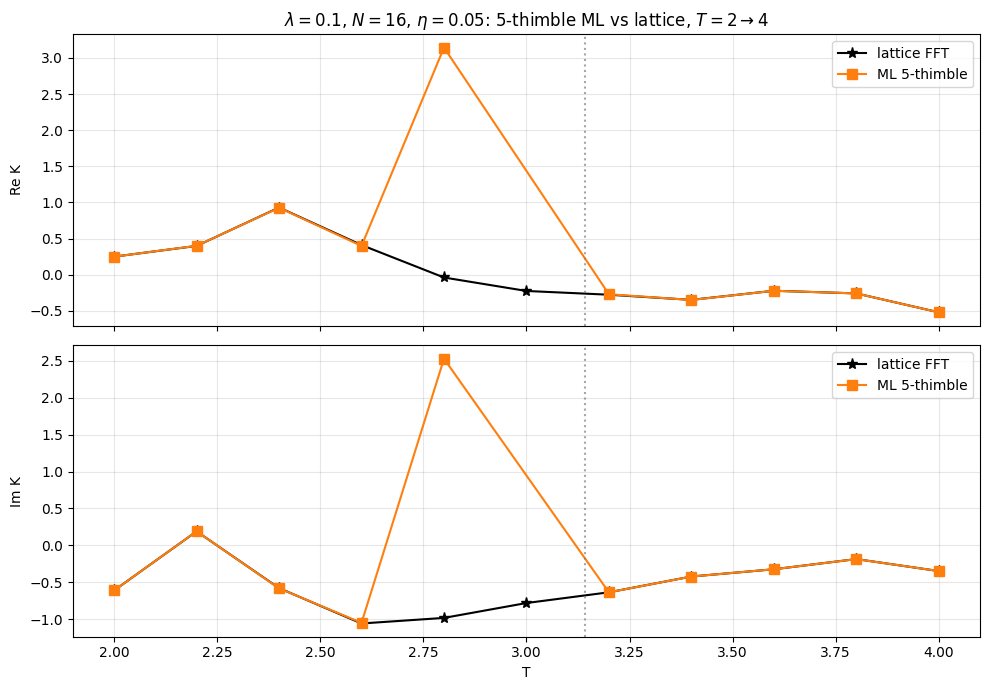

Saved plot: C:\xampp1\Quantum\runs\20261001_143307_MU_multithimble_lambda0.1_N16\summary_5thimble_vs_lattice_T2to4.png
PASS 9 / 11


In [11]:
scan_rows = []
comparison_csv = run_dir / "MU_lambda0p1_T2to4_dt0.2_5thimble_vs_lattice.csv"
lattice_csv = (
    Path("Re__Complex_Time_Code_")
    / "py_scripts_extracted"
    / "exact_check_Time_Loop_lambda0p1_T0to8_dt0.01.csv"
)
lattice_by_T = {}
with lattice_csv.open("r", encoding="utf-8") as handle:
    for row in csv.DictReader(handle):
        lattice_by_T[round(float(row["T"]), 2)] = complex(
            float(row["lattice_K_re"]), float(row["lattice_K_im"])
        )

print(f"LAMBDA={LAMBDA}  T_LIST={T_LIST}", flush=True)

for t_value in T_LIST:
    T = float(t_value)
    A_C = (T - 1j * ETA) / N
    print("\n" + "#" * 84, flush=True)
    print(f"T = {T}   lambda = {LAMBDA}", flush=True)
    print("#" * 84, flush=True)

    lattice_ref = lattice_by_T[round(T, 2)]
    trivial_saddle = np.zeros(D, dtype=np.complex128)
    try:
        bounce_saddle = first_bounce()
        has_bounce = True
    except RuntimeError as exc:
        print(f"No first bounce: {exc}")
        bounce_saddle = None
        has_bounce = False
    anchor = bounce_saddle if has_bounce else trivial_saddle
    bounce2_saddle = second_bounce(anchor)
    has_bounce2 = bounce2_saddle is not None
    print(f"bounce1={has_bounce}  bounce2={has_bounce2}", flush=True)

    saddles = [("trivial", trivial_saddle)]
    if has_bounce:
        saddles.append(("bounce", bounce_saddle))
    if has_bounce2:
        saddles.append(("bounce2", bounce2_saddle))

    trained = {}
    for offset, (label, saddle) in enumerate(saddles):
        print("\n" + "=" * 84, flush=True)
        print(f"*** STARTING ML TRAINING: {label} thimble at lambda={LAMBDA}, T={T} ***", flush=True)
        print("=" * 84, flush=True)
        model, history, seconds = train_thimble(label, saddle, SEED + offset)
        estimate, stderr, ess, block_scatter, blocks = estimate_thimble(model, SEED + offset)
        trained[label] = {"K": estimate, "stderr": stderr, "ESS": ess, "seconds": seconds}
        print(f"K_{label}={estimate:+.10f}  ESS/N={ess:.6f}  {seconds:.0f}s", flush=True)

    K0 = trained["trivial"]["K"]
    Kb1 = trained["bounce"]["K"] if has_bounce else 0.0j
    Kb2 = trained["bounce2"]["K"] if has_bounce2 else 0.0j
    K_ml = K0 + 2.0 * Kb1 + 2.0 * Kb2
    err = abs(K_ml - lattice_ref) / abs(lattice_ref)
    status = "PASS" if err < 0.05 else "FAIL"
    print(f"K_ML={K_ml:+.10f}")
    print(f"K_lattice={lattice_ref:+.10f}")
    print(f"error={100*err:.3f}%  {status}", flush=True)

    scan_rows.append({
        "lambda": LAMBDA,
        "T": T,
        "has_bounce": has_bounce,
        "has_bounce2": has_bounce2,
        "K_trivial_re": K0.real,
        "K_trivial_im": K0.imag,
        "K_bounce_re": Kb1.real,
        "K_bounce_im": Kb1.imag,
        "K_bounce2_re": Kb2.real,
        "K_bounce2_im": Kb2.imag,
        "K_ML_re": K_ml.real,
        "K_ML_im": K_ml.imag,
        "K_lattice_re": lattice_ref.real,
        "K_lattice_im": lattice_ref.imag,
        "complex_rel_err_vs_lattice": err,
        "trivial_ESS_over_N": trained["trivial"]["ESS"],
        "bounce_ESS_over_N": trained["bounce"]["ESS"] if has_bounce else float("nan"),
        "bounce2_ESS_over_N": trained["bounce2"]["ESS"] if has_bounce2 else float("nan"),
        "status": status,
    })
    with comparison_csv.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(scan_rows[0].keys()))
        writer.writeheader()
        writer.writerows(scan_rows)
    print(f"Wrote {len(scan_rows)} rows to {comparison_csv}", flush=True)

print("\n" + "=" * 100)
header = f"{'T':>6}  {'K_ML':>26}  {'K_lattice':>26}  {'err%':>8}  {'b1':>5}  {'b2':>5}  {'status':>8}"
print(header)
print("-" * len(header))
for row in scan_rows:
    kml = complex(row["K_ML_re"], row["K_ML_im"])
    klat = complex(row["K_lattice_re"], row["K_lattice_im"])
    print(
        f"{row['T']:6.2f}  {kml:+.6f}  {klat:+.6f}  "
        f"{100*row['complex_rel_err_vs_lattice']:7.3f}%  "
        f"{str(row['has_bounce']):>5}  {str(row['has_bounce2']):>5}  {row['status']:>8}"
    )

times = np.array([r["T"] for r in scan_rows])
ml = np.array([complex(r["K_ML_re"], r["K_ML_im"]) for r in scan_rows])
lat = np.array([complex(r["K_lattice_re"], r["K_lattice_im"]) for r in scan_rows])
# Keep the axis readable if one Monte Carlo estimate overflows.
sane = np.array([abs(m) < 50.0 * max(abs(l), 1e-6) for m, l in zip(ml, lat)])

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(times, lat.real, "k*-", lw=1.5, ms=8, label="lattice FFT")
axes[0].plot(times[sane], ml.real[sane], "C1s-", lw=1.5, ms=7, label="ML 5-thimble")
axes[1].plot(times, lat.imag, "k*-", lw=1.5, ms=8, label="lattice FFT")
axes[1].plot(times[sane], ml.imag[sane], "C1s-", lw=1.5, ms=7, label="ML 5-thimble")
for ax in axes:
    ax.axvline(np.pi, color="grey", ls=":", alpha=0.7)
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Re K")
axes[0].set_title(rf"$\lambda={LAMBDA}$, $N={N}$, $\eta={ETA}$: 5-thimble ML vs lattice, $T=2\to 4$")
axes[1].set_ylabel("Im K")
axes[1].set_xlabel("T")
fig.tight_layout()
plot_path = run_dir / "summary_5thimble_vs_lattice_T2to4.png"
fig.savefig(plot_path, dpi=150)
plt.show()
print(f"Saved plot: {plot_path.resolve()}")
print(f"PASS {sum(r['status']=='PASS' for r in scan_rows)} / {len(scan_rows)}")
